In [73]:
# !pip install GPyOpt

In [74]:
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from PIL import Image, ImageDraw
from ipywidgets import interact, IntSlider, fixed
import os
import cv2

In [75]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, IntSlider, fixed

def load_image(image_path):
    # Load and convert the image to RGB if not already in that mode
    image = Image.open(image_path).convert("RGB")
    return image

def extract_rgb_values(image, points):
    """
    Extract RGB values from the given image at specified points.
    
    Args:
        image: PIL Image object.
        points: List of (x, y) coordinates.

    Returns:
        List of RGB values at the given points.
    """
    return [image.getpixel(point) for point in points]

def display_image_with_pixel_value(image_path, x, y):
    # Load the image
    image = load_image(image_path)
    # Convert image to array for display purposes
    image_array = np.array(image)
    # Get the RGB value at the selected coordinates
    rgb_value = image.getpixel((x, y))
    # Create a copy of the image to draw the red dot
    draw = ImageDraw.Draw(image)
    dot_radius = 5
    draw.ellipse((x - dot_radius, y - dot_radius, x + dot_radius, y + dot_radius), fill='red', outline='red')
    # Display the image with the red dot
    plt.figure(figsize=(6, 6))  # Optional: Set figure size
    plt.imshow(image)
    plt.axis('on')
    plt.title(f'RGB value at ({x}, {y}): {rgb_value}')
    plt.show()

    return rgb_value

# Image path
image_path = 'IMG_5851.jpg'

# Load the image
image = load_image(image_path)

# Dimensions of the image
width, height = image.size

# Extract RGB values interactively
interact(display_image_with_pixel_value,
         image_path=fixed(image_path),
         x=IntSlider(min=0, max=width-1, step=1, value=width//2),
         y=IntSlider(min=0, max=height-1, step=1, value=height//2))

# Generate random points for RGB extraction (example with 20 points)
num_points = 20
random_points = [(np.random.randint(0, width), np.random.randint(0, height)) for _ in range(num_points)]

# Extract RGB values at these random points
rgb_values = extract_rgb_values(image, random_points)

# Print RGB values in the desired format
rgb_values_formatted = ', '.join([f"({r}, {g}, {b})" for r, g, b in rgb_values])
print("RGB values:")
print(rgb_values_formatted)


interactive(children=(IntSlider(value=973, description='x', max=1946), IntSlider(value=1517, description='y', …

RGB values:
(60, 53, 25), (178, 165, 133), (52, 24, 2), (103, 66, 47), (64, 52, 30), (119, 54, 12), (225, 222, 191), (187, 177, 152), (227, 226, 206), (123, 77, 28), (93, 41, 4), (155, 156, 96), (116, 113, 82), (245, 237, 218), (214, 205, 206), (248, 231, 215), (237, 236, 241), (76, 30, 15), (75, 106, 62), (94, 46, 10)


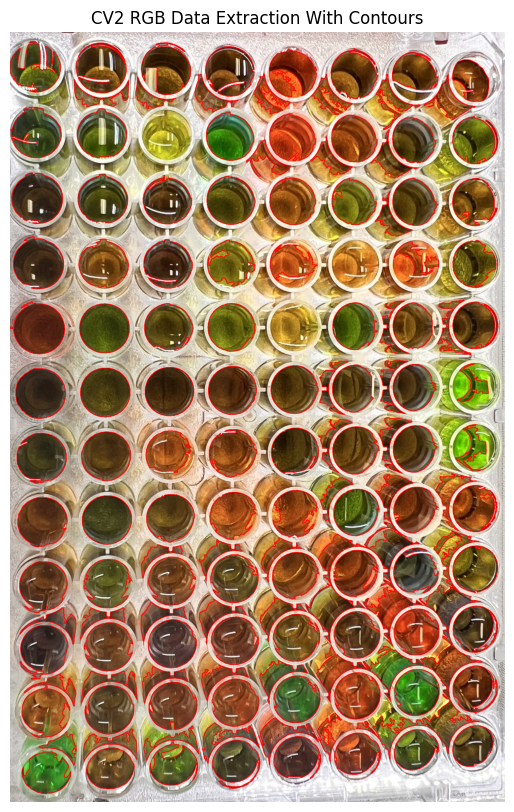

In [76]:
# Load the image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
image = cv2.bilateralFilter(image,9,75,75)
image_rgb = cv2.imread(image_path)

# Apply thresholding to isolate wells
ret, thresh = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY_INV)

# Adaptive Thresholding to handle varying illumination
# thresh = cv2.adaptiveThreshold(
#     image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 2
# )

# Find contours of the wells
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Helper function to get the centroid y-coordinate of a contour
def get_contour_y(contour):
    M = cv2.moments(contour)
    if M["m00"] != 0:
        return int(M["m01"] / M["m00"])  # Y-coordinate of the centroid
    return 0

# Sort contours by their y-coordinate
contours_ordered = sorted(contours, key=get_contour_y)

contour_plot = []
rgb_values = []

# Iterate through each detected contour
for contour in contours_ordered:
    if cv2.contourArea(contour) < 5000:
        continue  # Skip small contours

    contour_plot.append(contour)

    # Create a mask for the current well
    mask = np.zeros(image_rgb.shape[:2], dtype="uint8")
    cv2.drawContours(mask, [contour], -1, 255, -1)

    # Extract the ROI (well) using the mask
    well_pixels = cv2.bitwise_and(image_rgb, image_rgb, mask=mask)
    
    # Calculate the average BGR values
    mean_val = cv2.mean(image_rgb, mask=mask)[:3]
    rgb_values.append(mean_val[::-1]) # Reverse BGR output to RGB

output_image = image_rgb.copy()
cv2.drawContours(output_image, contour_plot, -1, (0, 0, 255), 2)
output_image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)  # Convert to RGB for matplotlib

# Double check contours
plt.figure(figsize=(12,10))
plt.imshow(output_image_rgb)
plt.axis('off')  # Hide axis
plt.title('CV2 RGB Data Extraction With Contours')
plt.show()

In [77]:
# Separate the RGB values into individual lists
R_values = [rgb[0] for rgb in rgb_values]
G_values = [rgb[1] for rgb in rgb_values]
B_values = [rgb[2] for rgb in rgb_values]

# Print the values in the required format
print("R values:")
print(", ".join(map(str, R_values)))

print("\nG values:")
print(", ".join(map(str, G_values)))

print("\nB values:")
print(", ".join(map(str, B_values)))

# Print lengths of the lists
print("Length of R values:", len(R_values))
print("Length of G values:", len(G_values))
print("Length of B values:", len(B_values))


R values:
99.68306179968378, 84.25625430341978, 83.73759741089299, 97.71882614683759, 104.12014693127901, 144.95668230795968, 107.25467477343122, 112.67351528782444, 123.40336953494848, 143.63994149714134, 166.898386214442, 129.50388622457416, 124.06939152522803, 137.26550270921132, 145.75152467196452, 67.19390159390159, 98.81542941341567, 58.44685650887574, 186.80794728119326, 139.03580772384709, 84.21921075455334, 94.67184969225785, 156.07161334240982, 133.6182052937379, 101.31244881244882, 67.307970071568, 80.57533913043477, 85.47976589822282, 113.10061264992666, 140.9230621568703, 89.41662288930581, 110.25508077123503, 86.65046574208239, 98.28747819084687, 168.42211908535205, 186.75408084525435, 122.75059297381965, 66.46589029097869, 95.14623037806766, 80.1964239820832, 128.03031517580615, 85.45994314769588, 110.0594190341557, 78.23282207327604, 104.04438321480433, 88.66547446071309, 69.10688285903376, 91.45554999060914, 122.75582318687137, 98.11105761515005, 88.91073772643739, 76.

In [78]:
# import numpy as np
# import GPyOpt

# # Constants
# max_volume = 270  # Maximum total volume constraint
# target_rgb = np.array([76, 0, 153])  # Target RGB (purple)

# # Provided CMY values
# C_values = np.array([143.98653699673, 95.56830677478278, 108.41887629083841, 182.79003829610198, 136.6751429815244, 92.63713330464526, 98.08110748319088, 28.297092637873085, 37.69406693145107, 90.854561035582, 118.72597022215743, 236.73765481855312, 5.365478745692884, 15.302652767476241, 37.35585601849161, 44.75585527732724, 94.31945560204096, 75.85321893517833, 31.295508813693157, 91.18435915585376, 46.83227815400834, 124.59237744728554, 53.67346146620047, 108.14888490914551, 49.66732729084347, 124.95856016634995, 71.83522304816695, 118.89635309087218, 22.398498866167024, 139.1462982791866, 85.564767931866, 112.89386602566994, 107.24362106893174, 95.0456584694017, 18.245344223407216, 30.725274120582114, 25.61995816370509, 73.50126637276955, 22.29782431369278, 181.38520988270022, 9.567015649430708, 113.4834043668695, 93.54956951312701, 77.45102678883596, 140.70379760222514, 112.71476404922196, 56.05128179058338, 117.08807383498042, 10.60829251031832, 108.15138220884897, 80.03539565813016, 79.51937518728059, 118.17910847671777, 101.55098810752514, 96.29705313819214, 77.12372280445061, 134.79076229531876, 170.31179965278307, 19.852904394710436, 98.01493960223664, 112.70890830126388, 85.10174645901509, 51.471196802392136, 120.40514984376733, 63.66539261023865, 81.60541466666048, 161.59855342168208, 112.58909490158933, 68.73424575899865, 109.99146890567515, 21.254705366601833, 104.77027923265462, 94.84829530476192, 228.01035312530036, 105.92598927191608, 52.0420632405664, 170.09612858693723, 145.2706481833455, 111.0998470625754, 127.84761448500531, 153.44255598565854, 5.816450460882815, 158.3932562148109, 1.7536000356631536, 135.65893838045574, 156.9509092039439, 86.5145870893901, 68.24591205369289, 75.87327756823584, 36.19120226175889, 167.1343110374844, 173.91184470653272, 65.51668131486828, 47.54403568939381, 112.87252142415771, 11.887977340542479])  # Replace with your actual C values
# M_values = np.array([81.78041065563364, 93.52796791848544, 94.70175770604371, 26.837737645681376, 116.28128882708201, 104.30901075499118, 94.89355540742287, 115.32514771791492, 126.81989549268883, 137.0262954374045, 44.49562406336879, 5.918396640187716, 196.76898432872727, 38.632128577161495, 141.21152424925168, 164.9341090953328, 90.07285272187505, 123.87323347693393, 99.96408862002889, 51.46682356904376, 120.05486346744023, 120.92515720669041, 141.42452199812777, 121.53302791700801, 110.39879623798642, 21.2599010241636, 31.162862144114566, 16.206124859355896, 78.03782267467598, 119.43289461962054, 48.735178410820616, 108.14147826003736, 134.4942014677002, 87.08288346975901, 145.58639222338635, 29.747189891192672, 84.92520455909823, 95.25797426346941, 120.9481227235389, 32.00418155033229, 118.98724187203953, 146.04815938057266, 111.17751877497518, 90.31775014034348, 88.65215725403878, 115.06345204455715, 104.57413927150776, 128.76604834354632, 118.8015796188829, 118.86623983812159, 85.10018895529817, 114.77470048009597, 36.73103650745724, 30.41816538345748, 84.5982516252426, 128.79208747768982, 55.80930978060946, 71.82357012509485, 147.13542263570483, 12.646948424803897, 11.755030470656008, 87.81001468966387, 159.58844313649217, 46.465005008706946, 93.97583685065295, 184.68172900990442, 50.112551023501716, 41.59141898012432, 101.09914241183097, 55.35776637403975, 109.88329904404306, 47.19704127187821, 143.9865428055156, 10.69901020698269, 103.06681533021077, 75.26614348344663, 60.607294523370406, 124.20323876985063, 53.71428142167846, 135.19548099074532, 64.09678238470578, 170.10413979883023, 6.929983160945036, 168.2333786526025, 7.622424557860279, 41.12237025621667, 87.12045004070859, 3.1075599050088707, 116.97308490831804, 123.41086506810099, 18.90540048553566, 84.33972719297853, 123.53152579048603, 82.23147996477618, 36.70890732454103, 123.80237545999579])  # Replace with your actual M values
# Y_values = np.array([44.233052347636324, 80.9037253067318, 66.87936600311788, 60.37222405821661, 17.04356819139361, 73.05385594036358, 77.02533710938626, 126.377759644212, 105.48603757586011, 42.11914352701347, 106.7784057144738, 27.34394854125914, 67.86553692557986, 216.06521865536223, 91.43261973225668, 60.310035627339964, 85.60769167608399, 70.27354758788772, 138.74040256627794, 127.34881727510246, 103.11285837855142, 24.482465346024046, 74.90201653567173, 40.3180871738465, 109.93387647117012, 123.7815388094864, 167.00191480771846, 134.8975220497719, 169.563678459157, 11.42080710119287, 135.7000536573134, 48.96465571429269, 28.26217746336809, 87.87145806083927, 106.16826355320644, 209.52753598822525, 159.45483727719665, 101.24075936376101, 126.75405296276828, 56.6106085669675, 141.44574247852978, 10.468436252557892, 65.2729117118978, 102.23122307082056, 40.644045143736044, 42.22178390622089, 109.37457893790886, 24.145877821473267, 140.59012787079877, 42.982377953029484, 104.86441538657171, 75.70592433262344, 115.08985501582498, 138.0308465090174, 89.10469523656522, 64.08418971785956, 79.39992792407179, 27.864630222122077, 103.0116729695847, 159.33811197295947, 145.5360612280801, 97.08823885132105, 58.940360061115705, 103.12984514752573, 112.35877053910838, 3.7128563234350995, 58.28889555481617, 115.81948611828633, 100.16661182917036, 104.65076472028512, 138.8619955893551, 118.03267949546715, 31.16516188972245, 31.290636667716967, 61.00719539787311, 142.69179327598695, 39.29657688969238, 0.5261130468038852, 105.18587151574613, 6.95690452424941, 52.460661629635695, 94.07940974028695, 104.67676062424407, 100.01302131173435, 126.71863706168402, 71.92672053983945, 96.36496286990132, 198.6465280412982, 77.15363752344615, 110.39793267014014, 83.96028847697994, 11.748428100488733, 80.95179289464572, 140.22448434583, 120.41857125130129, 134.30964719946175])  # Replace with your actual Y values

# # Fill in missing K values
# K_values = np.maximum(0, max_volume - (C_values + M_values + Y_values))

# # Combine into CMYK data
# CMYK_data = np.column_stack([C_values, M_values, Y_values, K_values])

# # Convert CMYK volumes to RGB
# def cmyk_to_rgb(cmyk_volumes):
#     V_c, V_m, V_y, V_k = cmyk_volumes
#     R = 255 * (1 - V_c / max_volume) * (1 - V_k / max_volume)
#     G = 255 * (1 - V_m / max_volume) * (1 - V_k / max_volume)
#     B = 255 * (1 - V_y / max_volume) * (1 - V_k / max_volume)
#     return np.array([R, G, B])

# # Objective function: Minimize norm between target RGB and actual RGB
# def objective_function(cmyk_volumes):
#     # Compute RGB
#     predicted_rgb = cmyk_to_rgb(cmyk_volumes)
#     # Compute distance to target RGB
#     return np.linalg.norm(predicted_rgb - target_rgb)

# # Bounds for CMYK volumes
# bounds = [
#     {'name': 'C', 'type': 'continuous', 'domain': (0, max_volume)},
#     {'name': 'M', 'type': 'continuous', 'domain': (0, max_volume)},
#     {'name': 'Y', 'type': 'continuous', 'domain': (0, max_volume)},
#     {'name': 'K', 'type': 'continuous', 'domain': (0, max_volume)},
# ]

# # # Define the Bayesian Optimization object
# # optimizer = GPyOpt.methods.BayesianOptimization(
# #     f=lambda x: np.apply_along_axis(objective_function, 1, x),  # Apply function batch-wise
# #     domain=bounds,
# #     acquisition_type='EI'  # Expected Improvement
# # )

# # # Run the optimization
# # optimizer.run_optimization(max_iter=100)

# # # Extract results
# # optimal_cmyk = optimizer.x_opt
# # optimal_rgb = cmyk_to_rgb(optimal_cmyk)
# # optimal_norm = optimizer.fx_opt

# # Prepare a list to store results
# results = []

# # Run multiple optimizations
# num_runs = 5  # Number of independent runs
# for run in range(num_runs):
#     np.random.seed(None)  # Set a new random seed for each run

#     optimizer = GPyOpt.methods.BayesianOptimization(
#         f=lambda x: np.apply_along_axis(objective_function, 1, x),
#         domain=bounds,
#         acquisition_type='EI'
#     )

#     optimizer.run_optimization(max_iter=100)

#     # Save results from this run
#     optimal_cmyk = optimizer.x_opt
#     optimal_rgb = cmyk_to_rgb(optimal_cmyk)
#     optimal_norm = optimizer.fx_opt

#     results.append({
#         "run": run + 1,
#         "optimal_cmyk": optimal_cmyk,
#         "optimal_rgb": optimal_rgb,
#         "optimal_norm": optimal_norm
#     })

# # Save results distinctly
# import json

# with open("optimization_results.json", "w") as f:
#     json.dump(results, f, indent=4)

# print("Results saved to optimization_results.json")


# print("Optimal CMYK volumes:", optimal_cmyk)
# print("Predicted RGB:", optimal_rgb)
# print("Distance to target RGB:", optimal_norm)

# # Compare with the actual data
# actual_rgbs = np.array([cmyk_to_rgb(cmyk) for cmyk in CMYK_data])
# errors = np.linalg.norm(actual_rgbs - target_rgb, axis=1)

# # Find the best CMYK match from your actual data
# best_match_index = np.argmin(errors)
# best_cmyk_from_data = CMYK_data[best_match_index]
# best_rgb_from_data = actual_rgbs[best_match_index]

# print("\nBest CMYK from data:", best_cmyk_from_data)
# print("Best RGB from data:", best_rgb_from_data)
# print("Distance to target RGB (from data):", errors[best_match_index])


In [84]:
import numpy as np
from scipy.optimize import minimize
import GPyOpt

# Target RGB value (purple)
target_rgb = np.array([76, 0, 153])

# Provided RGB values
R_values = np.array([99.68306179968378, 84.25625430341978, 83.73759741089299, 97.71882614683759, 104.12014693127901, 144.95668230795968, 107.25467477343122, 112.67351528782444, 123.40336953494848, 143.63994149714134, 166.898386214442, 129.50388622457416, 124.06939152522803, 137.26550270921132, 145.75152467196452, 67.19390159390159, 98.81542941341567, 58.44685650887574, 186.80794728119326, 139.03580772384709, 84.21921075455334, 94.67184969225785, 156.07161334240982, 133.6182052937379, 101.31244881244882, 67.307970071568, 80.57533913043477, 85.47976589822282, 113.10061264992666, 140.9230621568703, 89.41662288930581, 110.25508077123503, 86.65046574208239, 98.28747819084687, 168.42211908535205, 186.75408084525435, 122.75059297381965, 66.46589029097869, 95.14623037806766, 80.1964239820832, 128.03031517580615, 85.45994314769588, 110.0594190341557, 78.23282207327604, 104.04438321480433, 88.66547446071309, 69.10688285903376, 91.45554999060914, 122.75582318687137, 98.11105761515005, 88.91073772643739, 76.29655283505154, 98.88314116547211, 81.15320623916811, 90.21591641945052, 87.60028658558988, 88.03741002092124, 66.24484624340798, 73.99315022721197, 58.21336903634523, 98.17103090351497, 108.34473282442748, 82.52965929143477, 86.375, 98.0998833592535, 70.6364795425569, 156.9047445421813, 132.71145817225914, 87.75988797048979, 65.48886482095715, 165.21186106177225, 105.80633592349072, 132.06523206751055, 112.02636658769852, 84.37520654654182, 143.5341537916685, 160.70325470535053, 98.11228602063075, 68.56535459789617, 93.89216153636612, 125.09763738415351, 133.23539049699616, 111.07562060553882, 118.80318257956449, 110.39881329113925, 122.62549190423263, 74.37854750572889, 123.17849916045982, 130.9574399871759, 102.235285385586, 120.29440900562852, 98.98463687150839, 103.2914029352438, 116.1254724111867, 116.9940876656473, 102.75852082869237, 111.770719029743, 99.06501509054327, 81.10426122592871, 167.244139111999, 98.91407604532075, 117.05902008781132, 112.37135518960568, 91.46326783501505, 113.83025537440486, 74.81027969361938, 117.9299765535361, 86.62046997389034, 127.22660853169927, 115.30836408364083, 110.80426236292158, 139.8583111111111, 108.56337900782344, 68.29808453379769, 155.7797697752197, 76.72512699079556, 142.90518150323845, 115.7593539604871, 95.87292837078652, 142.42722858807537, 115.52125678192567, 132.0623428092371, 166.54933240853128, 108.71650684293827, 107.89849338000303, 128.5186533212011, 87.10088094638813, 84.9302359452374, 85.90748963161747, 132.3851841832364, 89.79600156121253, 80.49580833401825, 87.61047439431307, 109.4697498298162, 63.59395958050141])  # Replace with your actual R values
G_values = np.array([73.49346944387159, 55.322354831305944, 86.1165098156113, 64.56549069463573, 65.10897403193714, 49.04131908237748, 64.75652938702153, 59.356634855024005, 100.02422723475354, 84.64446217258343, 74.20090262582056, 99.14701504878452, 86.51195012123311, 91.84816375677303, 84.65172796155979, 77.4085239085239, 106.92818551782207, 110.40096153846154, 63.354352458369505, 68.41153500722402, 70.01274934952298, 97.31725785552317, 76.15439074200137, 74.10071013557135, 70.69727682227683, 54.233474300585556, 79.27126956521738, 74.58414816929556, 76.83147812580896, 79.98479671363305, 70.49253283302063, 104.030962306757, 67.48325398468226, 73.36625956247484, 76.49852841294997, 86.6883718169407, 109.83710002237638, 48.678366367145685, 82.36015918638073, 58.013400888497266, 85.17154308617233, 58.614405252832604, 75.33020201559579, 92.7703030552243, 103.30949100793089, 74.54845199508215, 74.57412309728657, 41.592343329368305, 93.8414505029116, 74.4174289841117, 71.65817799947493, 121.86581829896907, 82.66048613275163, 68.5840554592721, 69.76473623113633, 63.03156115663005, 53.27112513740648, 43.810834874323675, 62.40119620422347, 45.26094765372432, 69.84795942439254, 82.47832061068702, 128.89643002579066, 64.84221380471381, 67.10649300155521, 53.27597264613839, 84.56916275466023, 72.07774083810112, 62.79742468747865, 59.55161443173356, 102.93625419380305, 93.74297668858337, 66.14295358649788, 59.10064051943494, 95.83102525769141, 68.16025499136748, 79.17481712829786, 72.74226346729766, 66.03301662707838, 55.96019476981749, 99.80250620023496, 81.61892408519934, 85.0985794231597, 88.19748743718593, 90.66878955696203, 71.69070864249451, 72.6718667371761, 57.282085503939385, 72.67571033543061, 81.1432865731463, 78.74784240150093, 95.59923750566209, 67.55467065451764, 78.47100745059929, 72.45616717635066, 75.3135442192025, 83.55963037828474, 75.84280684104628, 63.84519455338651, 66.31862845027928, 66.1749123019233, 87.39204258460582, 68.34015712343253, 68.4743140378828, 76.00674505843313, 59.248674314629326, 87.1083858523039, 92.91007832898173, 71.40230968654254, 74.09421894218941, 84.41351127663977, 91.39093333333334, 60.067562067562065, 120.10867500395757, 70.87127634751496, 102.79597448726273, 77.73358186473867, 72.06688495640337, 76.15386235955057, 91.75082540299087, 103.20337679164305, 80.70634860147854, 81.22611409745102, 98.2236290848152, 114.8181403134987, 105.41552926903246, 70.53682355902342, 130.15817069618407, 91.21868748475238, 69.55516479552729, 59.733813261633195, 74.64522889783842, 99.42342473040283, 82.68026718856365, 127.30940270963676])  # Replace with your actual G values
B_values = np.array([41.023200659929884, 19.453331803228522, 37.699953157603375, 39.412296500335486, 22.723024335493086, 16.180917622523463, 21.87625712209858, 24.21135493283083, 58.98872180451127, 30.34756016487169, 33.94488512035011, 51.25301802546718, 52.78097217411384, 30.84491270319085, 36.62650157087415, 44.47841302841302, 58.48326550659557, 36.47629437869823, 26.23624812564123, 23.488968721933695, 38.87081526452732, 22.76502267573696, 37.66984343090538, 28.518657198192386, 28.444512694512696, 39.592713077423554, 43.9792, 24.667011633716367, 24.153550780912934, 25.434829346949744, 46.60795497185741, 26.247872155636617, 27.023059407990065, 29.107502348678032, 25.269979624179307, 29.57256484834095, 27.712911165808908, 33.180620884289745, 18.705018792836615, 40.510445350075265, 37.486318090726904, 22.222684870080474, 27.708057822974144, 21.71713475060652, 20.486167479614252, 28.832271524905927, 19.246492389146262, 24.195580041319726, 51.20910534674431, 39.989728775477445, 44.69913363087425, 9.157699742268042, 49.72296665627921, 42.46633448873484, 32.13642031041747, 22.41514494617335, 25.613843480727635, 20.29884939387713, 22.827419139267576, 32.860856219181656, 37.90080207596131, 43.677862595419846, 12.773313424731912, 31.494570707070707, 25.9952566096423, 21.1876907622764, 34.15537122282485, 28.06799907221277, 31.129824441560213, 37.24355242672443, 40.397671205841725, 39.90989240884638, 22.678523206751052, 30.19882425199614, 41.970099929184045, 22.89565717827261, 28.845730253965645, 34.67245905276001, 35.85262979300984, 30.97480250612912, 35.661401905756435, 36.3098033861278, 46.78863538527766, 57.79480737018426, 30.97440664556962, 37.21887109856109, 60.25784417415829, 25.222887157187756, 29.75125235442632, 44.745453870704374, 46.89354596622889, 50.302959383964975, 44.533212770397164, 36.98185941043084, 47.78715596330275, 59.540432167520606, 61.04345942824141, 63.354376257545276, 43.360243246816204, 35.72670934072654, 39.66670698762147, 39.349069433111865, 49.22782897718688, 62.98668790936449, 49.021100851248015, 53.766228815027894, 41.92369090576517, 49.941932114882505, 42.61890172048079, 49.027921279212784, 52.70701427684668, 46.799644444444446, 33.70524126079682, 39.038309324046224, 34.25791397682196, 55.28888973761601, 44.98730983581865, 47.82892461646003, 50.308778089887646, 41.8430763255001, 48.37326909061463, 63.81099001600487, 43.36864921102826, 66.1423517363374, 58.904276365849945, 58.8182185825498, 40.79058645859552, 53.83469268861054, 45.53544767016346, 47.92465846070607, 54.096751810572876, 54.016643379633436, 44.2780115092606, 45.639125255275694, 41.900796687221494])  # Replace with your actual B values

# Combine RGB values into a single array
RGB_data = np.column_stack([R_values, G_values, B_values])

# Define the objective function for BO: Minimize the Euclidean distance to the target RGB
def objective_function(x):
    return np.linalg.norm(x - target_rgb, axis=1).reshape(-1, 1)

# Define bounds for the RGB values
bounds = [{'name': 'R', 'type': 'continuous', 'domain': (0, 255)},
          {'name': 'G', 'type': 'continuous', 'domain': (0, 255)},
          {'name': 'B', 'type': 'continuous', 'domain': (0, 255)}]

# Set up Bayesian Optimization
optimizer = GPyOpt.methods.BayesianOptimization(
    f=objective_function,  # The objective function to minimize
    domain=bounds,         # The domain (bounds) of the optimization
    initial_design_numdata=5,  # Number of initial random points
    acquisition_type='EI'  # Expected Improvement
)

# Run the optimization
max_iter = 30  # Maximum number of iterations
optimizer.run_optimization(max_iter)

# Extract the optimal RGB values and distance
optimal_rgb = optimizer.x_opt
optimal_distance = optimizer.fx_opt

# Find the best match from provided data
distances_from_data = np.linalg.norm(RGB_data - target_rgb, axis=1)
best_match_index = np.argmin(distances_from_data)
best_rgb_from_data = RGB_data[best_match_index]
best_distance_from_data = distances_from_data[best_match_index]

# Display results
print("Optimal RGB from Bayesian Optimization:", optimal_rgb)
print("Distance to target RGB (from BO):", optimal_distance)
print("\nBest RGB from data:", best_rgb_from_data)
print("Distance to target RGB (from data):", best_distance_from_data)

Optimal RGB from Bayesian Optimization: [ 77.44871841   0.         152.52684987]
Distance to target RGB (from BO): 1.5240262723426536

Best RGB from data: [91.46326784 68.47431404 62.98668791]
Distance to target RGB (from data): 114.15007966980204


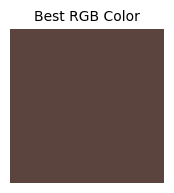

In [85]:
import matplotlib.pyplot as plt

# Convert RGB values to a 0-1 range for Matplotlib
rgb_normalized = [val / 255 for val in best_rgb_from_data]

# Create an image filled with the RGB color
color_patch = np.ones((10, 10, 3)) * rgb_normalized

# Display the color patch
plt.figure(figsize=(2, 2))
plt.imshow(color_patch)
plt.axis('off')
plt.title("Best RGB Color", fontsize=10)
plt.show()

In [86]:
best_match_index = np.argmin(errors)  # Index of the best match
best_distance_from_data = errors[best_match_index]  # Distance at that index

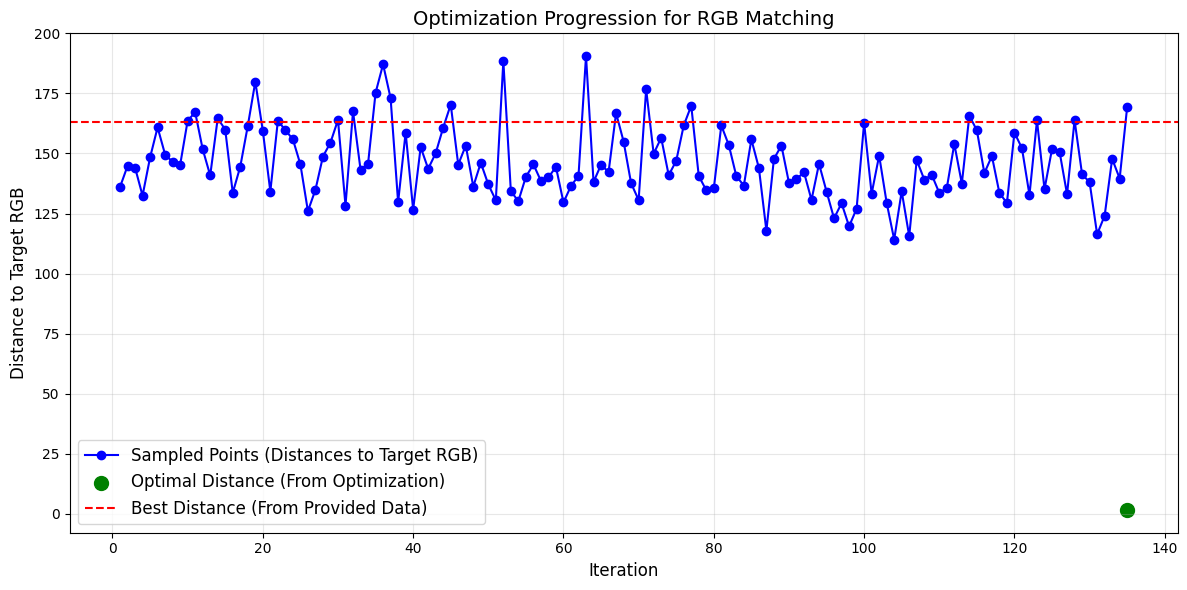

In [87]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming we have distances for visualization
iterations = np.arange(1, len(distances_from_data) + 1)

# Visualization
plt.figure(figsize=(12, 6))

# Plot distances from provided data
plt.plot(
    iterations,
    distances_from_data,
    marker='o',
    label="Sampled Points (Distances to Target RGB)",
    color="blue",
)

# Highlight the optimal distance from optimization
plt.scatter(
    len(iterations),
    optimal_distance,
    color="green",
    s=100,
    label="Optimal Distance (From Optimization)",
)

# Highlight the best distance from the given data
plt.axhline(
    best_distance_from_data,
    color="red",
    linestyle="--",
    label="Best Distance (From Provided Data)",
)

# Adding labels, title, and legend
plt.xlabel("Iteration", fontsize=12)
plt.ylabel("Distance to Target RGB", fontsize=12)
plt.title("Optimization Progression for RGB Matching", fontsize=14)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()

# Show the plot
plt.show()


In [83]:
# # Visualization
# plt.figure(figsize=(12, 6))
# iterations = np.arange(1, len(optimizer.Y) + 1)
# distances = optimizer.Y.flatten()

# # Plot optimization progression
# plt.plot(
#     iterations,
#     distances,
#     marker='o',
#     label="Sampled Points (Distances to Target RGB)",
#     color="blue",
# )

# # Highlight the optimal distance from BO
# plt.scatter(
#     iterations[-1],
#     optimal_norm,  # Use the correct variable
#     color="green",
#     s=100,
#     label="Optimal Distance (From BO)",
# )

# # Highlight the best distance from actual data
# plt.axhline(
#     best_distance_from_data,
#     color="red",
#     linestyle="--",
#     label="Best Distance (From Given Data)",
# )

# # Annotations and styling
# plt.xlabel("Iteration", fontsize=12)
# plt.ylabel("Distance to Target RGB", fontsize=12)
# plt.title("Bayesian Optimization for CMYK to RGB", fontsize=14)
# plt.legend(fontsize=12)
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()